In [1]:
import numpy as np, networkx as nx, matplotlib.pyplot as plt
from ou_hankel import OUNetwork, theoretical_rank, theoretical_hankel
from matplotlib.lines import Line2D

plt.rcParams.update({
    # Font Family
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    
    # Consistent Font Sizes
    'font.size': 13,          # Base default text size
    'axes.labelsize': 13,     # X and Y axis labels
    'axes.titlesize': 13,     # Subplot titles
    'xtick.labelsize': 13,    # X-axis tick labels
    'ytick.labelsize': 13,    # Y-axis tick labels
    'legend.fontsize': 10,   # Legend text
    'figure.titlesize': 10,   # Overall figure title
})


In [ ]:
# ----------------------------------------------------------------------
# configuration
# ----------------------------------------------------------------------
n, h, margin = 10, 0.3, 0.3
p_list = np.linspace(0.01, 0.9, 10)
n_graphs = 10           # graph replicates per p
M = n                 # sensors drawn per graph
EPS = np.finfo(float).eps
 
C_LINK = "tab:blue"    # i ~> j         
C_NOLINK = "tab:orange"   # no causal link
P_INSET = 0.2         # density of the graph shown in the inset
PATH_HOPS = 2          # preferred length of the highlighted i ~> j route
OUTDIR = "plots"

In [ ]:
def hankel_stats(sys, sensors, n_p, l = 2*n):
    """(rank, cond, representable) for the theoretical Hankel of `sensors`.

    `n_p` is the theoretical rank |R_sensors|; the condition number is taken
    across the singular values Theorem 1 predicts to be nonzero.
    """
    H = theoretical_hankel(sys, sensors, h, l)
    sv = np.linalg.svd(H, compute_uv=False)
    rk = int(np.linalg.matrix_rank(H))
    cond = sv[0] / sv[min(n_p, len(sv)) - 1] if n_p > 0 else np.inf
    return rk, cond, cond < 1.0 / (max(H.shape) * EPS)


def balanced_pairs(G, sensors, rng=None, k=None):
    """Return all linked and unlinked ordered sensor pairs (i, j)."""
    return [
        (i, j, nx.has_path(G, i, j))
        for i in sensors
        for j in sensors
        if i != j
    ]

def pick_demo_pairs(G, sensors):
    """One linked pair with its shortest path, plus an unlinked pair that is
    disjoint from that path (so the inset stays unambiguous)."""
    lengths = dict(nx.all_pairs_shortest_path_length(G))
    linked = [(i, j, lengths[i][j]) for i in sensors for j in sensors
              if i != j and j in lengths[i]]
    unlinked = [(i, j) for i in sensors for j in sensors
                if i != j and j not in lengths[i]]
    if not linked or not unlinked:
        return None
    def clearance(pair, sp):
        return min(min(abs(a - b) % n, n - abs(a - b) % n)
                   for a in pair for b in sp)

    for i1, j1, _ in sorted(linked, key=lambda t: abs(t[2] - PATH_HOPS)):
        sp = nx.shortest_path(G, i1, j1)
        cand = [(i, j) for i, j in unlinked if i not in sp and j not in sp]
        if cand:
            return (i1, j1, sp), max(cand, key=lambda pr: clearance(pr, sp))
    i1, j1, _ = min(linked, key=lambda t: abs(t[2] - PATH_HOPS))
    return (i1, j1, nx.shortest_path(G, i1, j1)), unlinked[0]


In [4]:
# ----------------------------------------------------------------------
# experiment
# ----------------------------------------------------------------------
rec = []                # (rk_j, rk_ij, np_j, np_ij, linked, resolvable)
inset_data = None       # (G, sensors) of the representative graph
for ip, p in enumerate(p_list):
    for r in range(n_graphs):
        seed = 169341 + 31 * r + int(1e4 * p)
        G = nx.erdos_renyi_graph(n, p, directed=True, seed=seed)
        sys = OUNetwork(G, seed=100 + r, weight_range=(0.2, 0.4),
                        spectral_margin=margin)

        rng = np.random.default_rng(500 + r + 7 * ip)
        sensors = sorted(rng.choice(n, M, replace=False).tolist())

        if r == 0 and abs(p - P_INSET) == min(abs(p_list - P_INSET)):
            inset_data = (G, sensors)

        reach = {s: set(sys.output_reachable_set([s])) for s in sensors}
        cache = {}      # single-sensor Hankel stats, reused across pairs

        for i, j, linked in balanced_pairs(G, sensors, rng):
            if j not in cache:
                cache[j] = hankel_stats(sys, [j], len(reach[j]))
            rk_j, _, ok_j = cache[j]

            np_ij = len(reach[i] | reach[j])
            rk_ij, _, ok_ij = hankel_stats(sys, sorted([i, j]), np_ij)

            rec.append((rk_j, rk_ij, len(reach[j]), np_ij, linked, ok_j and ok_ij))

rec = np.array(rec, float)
rk_j, rk_ij, np_j, np_ij, linked, res = rec.T
linked, res = linked.astype(bool), res.astype(bool)

# ----------------------------------------------------------------------
# numerical validation of the iff
# ----------------------------------------------------------------------
eq = rk_j[res] == rk_ij[res]
tp = (eq & linked[res]).sum()
tn = (~eq & ~linked[res]).sum()
print(f"resolvable pairs           : {res.sum():.0f} / {len(res)}")
print(f"  linked   & rho equal     : {tp:.0f} / {linked[res].sum():.0f}")
print(f"  unlinked & rho different : {tn:.0f} / {(~linked[res]).sum():.0f}")
print(f"  iff holds                : {(tp + tn) / res.sum():.4f}")
# gap predicted by Theorem 1: rho(H_ij) - rho(H_j) = |R_i \ R_j|
print(f"  max |gap - |R_i\\R_j||    : "
      f"{np.abs((rk_ij - rk_j) - (np_ij - np_j))[res].max():.0f}")

resolvable pairs           : 2665 / 9000
  linked   & rho equal     : 813 / 813
  unlinked & rho different : 1852 / 1852
  iff holds                : 1.0000
  max |gap - |R_i\R_j||    : 0


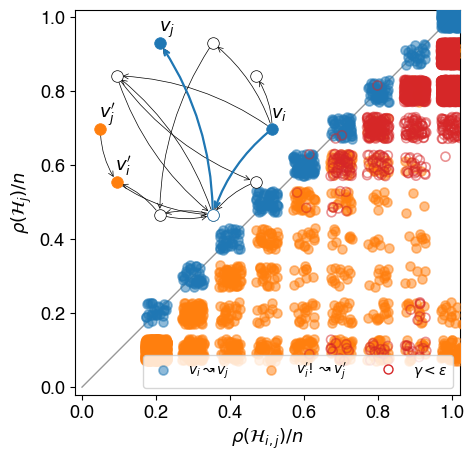

In [5]:
# ----------------------------------------------------------------------
# figure
# ----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], color="0.6", lw=1, zorder=0)

C_UNRES = "tab:red"          # unresolvable pairs: red, open  ("red" for a purer hue)

rj = np.random.default_rng(0)
for c, lk, lbl in [(C_LINK,   True,  r"$v_i \rightsquigarrow v_j$"),
                   (C_NOLINK, False, r"$v_i' !\rightsquigarrow v_j'$")]:
    for ok, fc, ec, z in [(True,  c,      c,       3),    # resolvable: filled, class colour
                          (False, "none", C_UNRES, 4)]:   # unresolvable: open, red, ON TOP
        m = (linked == lk) & (res == ok)
        if not m.any():
            continue
        jt = 0.03*np.random.uniform(-1,1,(m.sum(),2))
        ax.scatter(rk_ij[m] / n + jt[:, 0], rk_j[m] / n + jt[:, 1],
                   s=42, facecolor=fc, edgecolor=ec, linewidth=1.2, alpha=0.5,
                   label=lbl if ok else None, zorder=z)

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([], [], ls="none", marker="o", markersize=6.5,
                      markerfacecolor="none", markeredgecolor=C_UNRES,
                      label=r"$\gamma < \epsilon$"))


ax.set_xlabel(r"$\rho(\mathcal{H}_{i,j})/n$")
ax.set_ylabel(r"$\rho(\mathcal{H}_j)/n$")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_aspect("equal")
ax.legend(handles=handles, frameon=True, loc="lower right", ncols = 3)


# ----------------------------------------------------------------------
# inset: representative graph, linked pair + unlinked pair
# ----------------------------------------------------------------------
demo = pick_demo_pairs(*inset_data) if inset_data else None
if demo is not None:
    Gx, _ = inset_data
    (i1, j1, sp), (i2, j2) = demo
    pos = nx.circular_layout(Gx)

    ax_in = ax.inset_axes([0.02, 0.42, 0.54, 0.54])
    ax_in.set_frame_on(False)

    # nodes first
    rest = [v for v in Gx if v not in (i1, j1, i2, j2)]
    for nodes, fc, ec, sz in [
        (rest, "white", "black", 70),
        (sp[1:-1], "white", C_LINK, 70),
        ([i1, j1], C_LINK, C_LINK, 70),
        ([i2, j2], C_NOLINK, C_NOLINK, 70),
    ]:
        nx.draw_networkx_nodes(
            Gx, pos, nodelist=nodes, ax=ax_in, node_size=sz,
            node_color=fc, edgecolors=ec, linewidths=0.5
        )

    # edges on top of nodes
    nx.draw_networkx_edges(
        Gx, pos, ax=ax_in, edge_color="k", width=0.5,
        arrows=True, arrowsize=9, arrowstyle="->",
        connectionstyle="arc3,rad=0.15",
        node_size=70, min_source_margin=2, min_target_margin=2
    )

    # shortest path highlighted
    nx.draw_networkx_edges(
        Gx, pos, ax=ax_in, edgelist=list(zip(sp, sp[1:])),
        edge_color=C_LINK, width=1.6, arrows=True, arrowsize=9,
        arrowstyle="->", connectionstyle="arc3,rad=0.15",
        node_size=70, min_source_margin=2, min_target_margin=2
    )

    for s, txt in [(i1, "$v_i$"), (j1, "$v_j$"), (i2, "$v_i'$"), (j2, "$v_j'$")]:
        ax_in.annotate(txt, pos[s], textcoords="offset points",
                       xytext=(5, 8), ha="center")

    ax_in.set_axis_off()

plt.savefig(f"plots/Figure2.pdf")
plt.show()
